# Comet outgassing: the rocket effect on 2P/Encke

**The question.** Near perihelion a comet's ice sublimates and the escaping gas pushes back on the
nucleus. That *non-gravitational* acceleration is thousands of times larger than an asteroid's
Yarkovsky push. An orbit computed from gravity alone drifts away from the comet within a single
return. How big is the push on 2P/Encke (the comet with the shortest known period, 3.3 years),
which way does it point, and do we get the same answer as JPL?

PyRoOrb uses the standard Marsden et al. (1973) model: radial, transverse and normal accelerations
$A_1, A_2, A_3$ (au/day²) scaled by the water-sublimation curve $g(r)$, which switches the force on
inside ~3 au. For a comet designation, every fit tries gravity-only, then $A_1$, $A_1A_2$ and
$A_1A_2A_3$, and keeps the richest model the data justify.

In [1]:
# Load the PyRoOrb settings file (.env: data folders) before the engine is imported.
from pyroorb.envfile import load_env_file
load_env_file()

import warnings
import numpy as np
import matplotlib.pyplot as plt
import pyroorb

# Future UTC dates make astropy warn that leap seconds are not yet known; harmless here.
warnings.filterwarnings("ignore", message=".*dubious year.*")
plt.rcParams.update({"figure.figsize": (8, 4.5), "figure.dpi": 110, "axes.grid": True,
                     "grid.alpha": 0.3})
print("PyRoOrb", pyroorb.__version__)

PyRoOrb 0.9.0


## 1. Fetch, and keep the recent apparitions

Encke has been observed since the 18th century, but its outgassing changes from one return to the
next, so no single set of constant $A$'s spans two centuries. (A fit of the whole archive is also
slow.) We keep the same span JPL's current solution uses: November 2018 onward, the 2020, 2023 and
2026–27 returns. The radar list is cut to the same span.

In [2]:
from astropy.time import Time

everything = pyroorb.fetch_observations("2P")
cut = Time("2018-11-01").jd
obs = pyroorb.Observations(
    [o for o in everything if o["jd_utc"] >= cut],
    {**everything.meta, "radar": [r for r in everything.meta.get("radar") or [] if r["jd_utc"] >= cut]})
print(f"{len(everything)} observations in the archive, {len(obs)} since 2018-11")

6949 observations in the archive, 1795 since 2018-11


## 2. The automatic fit

In [3]:
fit = pyroorb.fit_orbit(obs, designation="2P")
print(f"{fit.n_observations()}/{fit.n_total_observations()} observations kept, rms {fit.rms_residual():.3f}\", "
      f"{fit.n_oppositions()} apparitions, model: {fit.nongrav_model}")
for k, v in fit.nongrav_params.items():
    lo, hi = fit.rational_nongrav_intervals()[k]
    print(f"  {k} = {v:+.3e}  (-{lo:.1e} / +{hi:.1e}) au/day^2   [{abs(v) / lo:.0f} sigma]")

disc = fit.nongrav_discovery["comet"]       # the model ladder it climbed (internal API, may change)
print(f"\n{'model':8s} {'rms':>6s}  coefficients")
print(f"{'gravity':8s} {disc['rms0']:6.3f}")
for name, m in disc["compare"].items():
    print(f"{name:8s} {m['rms']:6.3f}  " + ", ".join(f"{k}={v:.2e}" for k, v in m["params"].items()))

1640/1795 observations kept, rms 0.585", 9 apparitions, model: comet3


  A1 = +8.388e-11  (-2.1e-11 / +2.0e-11) au/day^2   [4 sigma]
  A2 = +5.597e-12  (-2.0e-13 / +2.0e-13) au/day^2   [28 sigma]
  A3 = +8.956e-10  (-1.7e-10 / +1.7e-10) au/day^2   [5 sigma]

model       rms  coefficients
gravity   1.156
comet1    1.098  A1=5.17e-10
comet2    1.047  A1=3.60e-11, A2=7.07e-12
comet3    1.056  A1=2.28e-11, A2=7.32e-12, A3=1.33e-09


## 3. What gravity alone does: it throws observations away

A gravity-only fit (non-gravitational discovery switched off, internal `fit_object.fit_orbit`) can
still return a small rms. It gets there by **rejecting** the observations it cannot fit, and those
pile up where the comet is most active. The plot shows every observation's residual under each
orbit; perihelion passages are marked.

gravity only: 1572/1795 kept, rms 0.582"
outgassing  : 1640/1795 kept, rms 0.585"


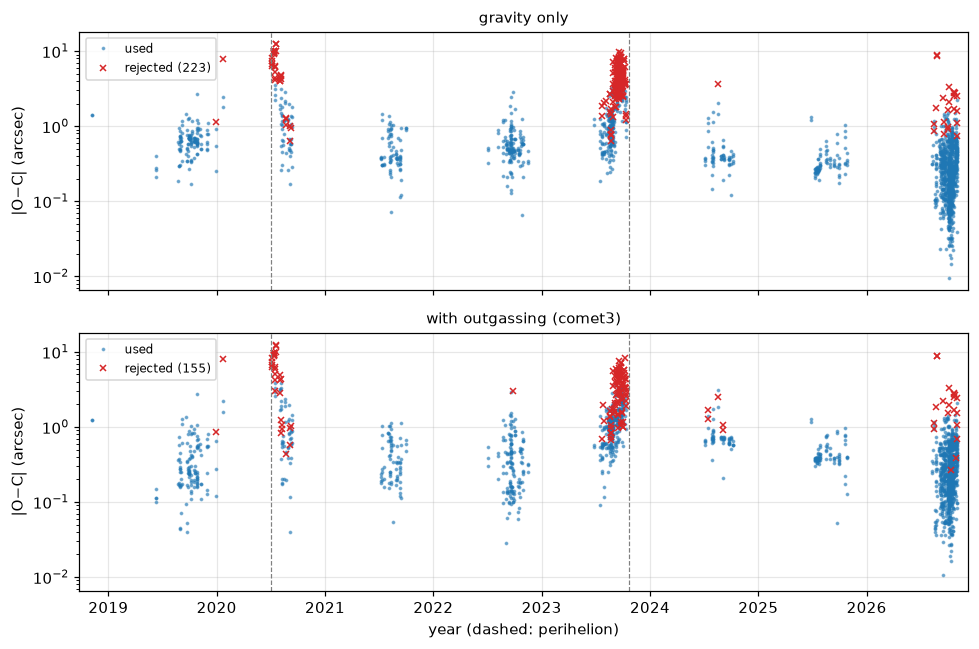

In [4]:
from pyroorb import fit_object

grav = fit_object.fit_orbit(list(obs), pyroorb.obscodes(), desig="2P", meta=obs.meta, auto_nongrav=False)
print(f"gravity only: {grav.n_observations()}/{grav.n_total_observations()} kept, rms {grav.rms_residual():.3f}\"")
print(f"outgassing  : {fit.n_observations()}/{fit.n_total_observations()} kept, rms {fit.rms_residual():.3f}\"")

tp, period = fit.perihelion_time()[0], fit.period()[0] * 365.25
perihelia = [tp + k * period for k in range(-2, 2)]
yr = lambda jd: Time(jd, format="jd").decimalyear

fig, axes = plt.subplots(2, 1, figsize=(9, 6), sharex=True, sharey=True)
for ax, f, title in ((axes[0], grav, "gravity only"), (axes[1], fit, f"with outgassing ({fit.nongrav_model})")):
    res = f.residuals()
    t = yr(np.array([r["jd_utc"] for r in res]))
    tot = np.array([np.hypot(r["d_ra_arcsec"], r["d_dec_arcsec"]) for r in res])
    inc = np.array([r["included"] for r in res])
    ax.semilogy(t[inc], tot[inc], ".", ms=3, alpha=0.5, label="used")
    ax.semilogy(t[~inc], tot[~inc], "x", ms=4, color="C3", label=f"rejected ({(~inc).sum()})")
    for p in perihelia:
        ax.axvline(yr(p), color="0.5", ls="--", lw=0.8)
    ax.set_title(title, fontsize=10); ax.set_ylabel("|O−C| (arcsec)"); ax.legend(fontsize=8, loc="upper left")
axes[1].set_xlim(yr(cut) - 0.1, yr(max(r["jd_utc"] for r in res)) + 0.1)
axes[1].set_xlabel("year (dashed: perihelion)"); plt.tight_layout(); plt.show()

## 4. Compare with JPL

JPL's current solution for Encke fits $A_1$ and $A_2$ only. For a like-for-like comparison we also
force that two-parameter model (`comet2`) onto the gravity fit's observation set
(`refine_nongrav` — internal API, may change).

JPL orbit K273/24 data 2018-11-05 to 2026-10-21


JPL (A1, A2)                      A1 = 1.030e-10 ± 4.5e-11  A2 = 3.242e-12 ± 4.6e-13
PyRoOrb comet2, strict obs set    A1 = 1.084e-10 ± 2.1e-11  A2 = 3.294e-12 ± 2.1e-13
PyRoOrb automatic (comet3)        A1 = 8.388e-11 ± 2.1e-11  A2 = 5.597e-12 ± 2.0e-13  A3 = 8.956e-10 ± 1.7e-10


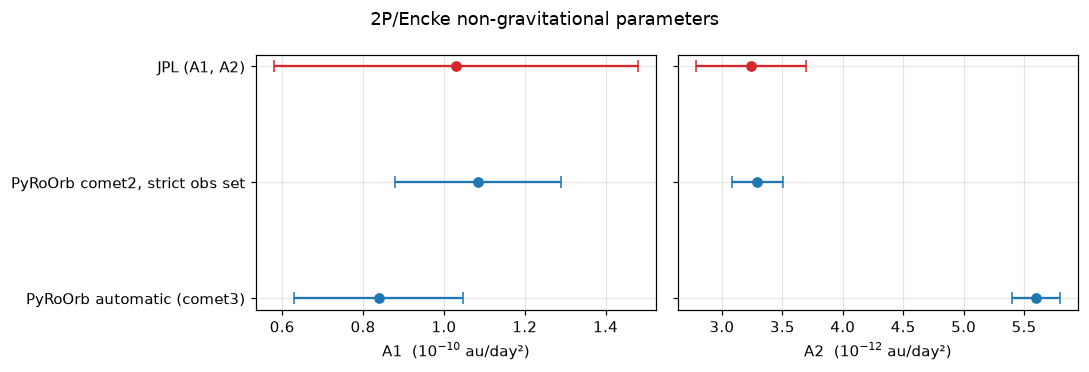

In [5]:
import json, urllib.request

sbdb = json.load(urllib.request.urlopen("https://ssd-api.jpl.nasa.gov/sbdb.api?sstr=2P"))
jpl = {p["name"]: (float(p["value"]), float(p["sigma"])) for p in sbdb["orbit"]["model_pars"]}
print("JPL orbit", sbdb["orbit"]["orbit_id"], "data", sbdb["orbit"]["first_obs"], "to", sbdb["orbit"]["last_obs"])

c2 = fit_object.refine_nongrav(grav, model="comet2", revert_if_worse=False)
sol = {"JPL (A1, A2)": {k: jpl[k] for k in ("A1", "A2")},
       "PyRoOrb comet2, strict obs set": {k: (v, c2.rational_nongrav_intervals()[k][0])
                                          for k, v in c2.nongrav_params.items()},
       f"PyRoOrb automatic ({fit.nongrav_model})": {k: (v, fit.rational_nongrav_intervals()[k][0])
                                                    for k, v in fit.nongrav_params.items()}}
for name, d in sol.items():
    print(f"{name:34s}" + "  ".join(f"{k} = {v:.3e} ± {s:.1e}" for k, (v, s) in d.items()))

fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
for ax, k, scale in ((axes[0], "A1", 1e-10), (axes[1], "A2", 1e-12)):
    for j, (name, d) in enumerate(sol.items()):
        if k in d:
            ax.errorbar(d[k][0] / scale, j, xerr=d[k][1] / scale, fmt="o", capsize=4, color=f"C{3 if j == 0 else 0}")
    ax.set_yticks(range(len(sol)), list(sol) if k == "A1" else [""] * len(sol)); ax.invert_yaxis()
    ax.set_xlabel(f"{k}  ($10^{{{int(np.log10(scale))}}}$ au/day²)")
plt.suptitle("2P/Encke non-gravitational parameters"); plt.tight_layout(); plt.show()

**Result.** The outgassing is unmistakable. On the same observations, the gravity-only orbit
leaves a ~10% larger residual (1.16″ against 1.05″ for the outgassing models in the ladder; the
F-tests put that at $p < 10^{-60}$). Left to its own
rejection, it can reach a similar rms only by discarding ~70 more observations, clustered around
the perihelia (top panel). The Marsden model keeps them.
The push is mostly **transverse** ($A_2 > 0$, along the motion). That is the classic Encke
signature, attributed to a delayed, prograde-rotating jet (Whipple, 1950).

On the same two-parameter model and a comparable data set, PyRoOrb reproduces JPL's $A_1$ and
$A_2$ within their 1σ uncertainties.

**Honest caveat.** The automatic fit keeps more observations near perihelion. On those, the data
justify a third (normal, $A_3$) component, and $A_2$ moves to ~$5.5\times10^{-12}$, many formal
σ from JPL's value. So for an active comet the coefficients depend on the model ladder and on which
observations are trusted, by more than their formal error bars suggest. Real outgassing is also
asymmetric about perihelion and changes between returns, which a constant-$A$ model only
approximates.